本 notebook 是 [M02.1 线性代数](../notes/01-linear-algebra.qmd) 的实例讲解。

1. 1. 投影与残差正交
2. 2. SVD 截断与 PCA 对齐
3. 3. 条件数与正定性

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.decomposition import PCA

from semiai.plotting import BLUE, GRAY, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)


## 1. 投影与残差正交

用 QR 得到列空间的正交基，比较投影与最小二乘解。残差正交和投影幂等都是可验证的几何性质。

In [2]:
A = rng.normal(size=(12, 3))
y = rng.normal(size=12)
Q, _ = np.linalg.qr(A, mode="reduced")
P = Q @ Q.T
yhat = P @ y
w = np.linalg.lstsq(A, y, rcond=None)[0]
print("投影与 lstsq 差:", np.linalg.norm(yhat - A @ w))
print("残差正交误差:", np.linalg.norm(A.T @ (y - yhat)))
print("幂等误差:", np.linalg.norm(P @ P - P))
assert np.allclose(yhat, A @ w) and np.allclose(P @ P, P)

投影与 lstsq 差: 6.459137513653699e-16
残差正交误差: 1.5574140529624952e-15
幂等误差: 9.302603748120296e-16


读法：三种误差均应接近浮点舍入量级，说明两种计算路径给出同一个投影；数值上不必显式构造逆矩阵。

## 2. SVD 截断与 PCA 对齐

先按列中心化，再用 SVD 重构；用投影矩阵比较主子空间，避免特征向量正负号带来的假差异。

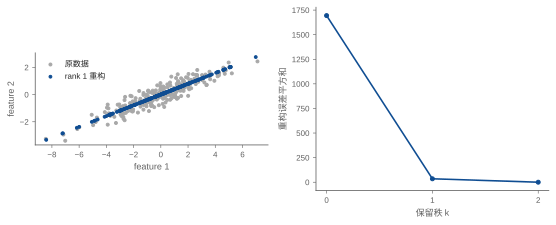

PCA 子空间误差: 0.0
rank 1 误差 / 丢弃奇异值平方和: 34.685790821922225 34.685790821922204


In [3]:
rng = np.random.default_rng(10)
X = rng.normal(size=(240, 2)) @ np.array([[2.6, 1.0], [0.0, 0.4]])
X -= X.mean(axis=0)
U, s, Vt = np.linalg.svd(X, full_matrices=False)
X1 = (U[:, :1] * s[:1]) @ Vt[:1]
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2))
axes[0].scatter(*X.T, s=9, color=GRAY, label="原数据")
axes[0].scatter(*X1.T, s=8, color=BLUE, label="rank 1 重构")
axes[0].set(xlabel="feature 1", ylabel="feature 2", aspect="equal")
axes[0].legend()
errors = [np.linalg.norm(X - (U[:, :k] * s[:k]) @ Vt[:k]) ** 2 for k in range(3)]
axes[1].plot(range(3), errors, "o-", color=BLUE)
axes[1].set(xlabel="保留秩 k", ylabel="重构误差平方和", xticks=range(3))
fig.tight_layout()
plt.show()


pca = PCA(n_components=1).fit(X)
print("PCA 子空间误差:", np.linalg.norm(pca.components_.T @ pca.components_ - Vt[:1].T @ Vt[:1]))
print("rank 1 误差 / 丢弃奇异值平方和:", np.linalg.norm(X - X1) ** 2, s[1] ** 2)
assert np.allclose(np.linalg.norm(X - X1) ** 2, s[1] ** 2)
assert np.allclose(pca.components_.T @ pca.components_, Vt[:1].T @ Vt[:1])

读法：截断后的误差由丢弃的奇异值决定；PCA 和 SVD 的子空间一致。若有重复奇异值，还要比较整个简并子空间而非某一列。

## 3. 条件数与正定性

让同样大小的右端项扰动沿最小奇异方向进入，观察解的放大；再用 Cholesky 检查正定矩阵。

In [4]:
rows = []
for eps in (1e-1, 1e-3, 1e-6):
    A = np.diag([1.0, eps])
    b = np.array([1.0, 0.0])
    db = np.array([0.0, 1e-8])
    relative = np.linalg.norm(np.linalg.solve(A, b + db) - np.linalg.solve(A, b)) / np.linalg.norm(
        np.linalg.solve(A, b)
    )
    rows.append((np.linalg.cond(A), relative, relative / np.linalg.norm(db)))
print(pd.DataFrame(rows, columns=["condition number", "relative solution change", "amplification"]))
B = np.array([[2.0, 0.5], [0.5, 1.0]])
L = np.linalg.cholesky(B)
print("Cholesky 重构误差:", np.linalg.norm(B - L @ L.T))
assert np.allclose(B, L @ L.T)

   condition number  relative solution change  amplification
0              10.0              1.000000e-07           10.0
1            1000.0              1.000000e-05         1000.0
2         1000000.0              1.000000e-02      1000000.0
Cholesky 重构误差: 4.440892098500626e-16


读法：这是沿最敏感方向设计的扰动，所以误差放大接近条件数；任意扰动通常达不到这个最坏界。Cholesky 适用于对称正定矩阵，不能用它证明一般非对称矩阵的性质。

## 小结

列空间决定可表示的输出，零空间决定不可辨认的参数；SVD 统一了投影、低秩近似与 PCA。条件数说明数据对扰动的敏感性，正定性则决定二次型与分解能否使用。先确认这些结构，再选择数值算法。